# Model selection for label distributions

**Question:** which model should produce the topic and format label distributions?

**Data:** five models labelled the same 2,000 parallel Nemotron-CC documents in six
languages (English, Finnish, German, Hungarian, Icelandic, Ukrainian) with both
taxonomies (26 labels each, including `Other` and `Bad example`), using
`generate_label_distributions.py` with the rotated prompt order. Within a language,
every model saw exactly the same prompt for each document; each language used its
own seed, so letter orders differ between languages.

**Criteria** (no human labels exist, so accuracy can only be approximated):

| Section | Criterion | Why it matters |
|---|---|---|
| 2 | Confidence and use of `Other` / `Bad example` | Soft labels need informative, not one-hot, distributions; fallback labels should be rare |
| 3 | Letter bias | The answer should depend on the content, not on which letter a label got |
| 4 | Agreement with the other models' consensus, and log loss / calibration against it | Best available stand-in for accuracy and soft-label quality without gold labels |
| 5–6 | Multilingual consistency | A parallel document should get the same label in every language |
| 7 | Label mix | Flags models that over- or under-use particular labels |
| 8 | Cost per 1,000 documents | Production runs will be large |
| 9 | Agreement with WebOrganizer-405B | Only if those runs exist; skipped otherwise |
| 10 | Decision table | All criteria side by side, with ranks |
| Appendix | Spot checks of `Other` / `Bad example` | Whether the fallback labels are used as intended |

**Running it:** on Roihu, `module load python-vllm/0.19.1` provides pandas,
matplotlib and JupyterLab; locally, use the `mwo-local` venv. Loading the 120 result
files takes a few minutes over the network mount. Section 9 downloads WebOrganizer's
label fields (no text) the first time and caches them in `data/weborganizer_samples/`.

**Common modifications** (parameter cell): add or remove models in `MODELS`; restrict
`LANGUAGES` or `LABEL_TYPES`; point `RESULTS_DIR` at another set of runs. Missing
files are listed in section 1 and left out of the comparisons that need them, rather
than stopping the notebook.

## Setup

Imports, the repository root, and the project's evaluation code. Loading, validation
and metrics come from `scripts/data_analysis/distribution_metrics.py`; the per-language
comparison with English is `compare` from `evaluate_multilingual_distributions.py`; the
WebOrganizer comparison uses `evaluate_distribution_reference.py`. The notebook
therefore computes exactly what the evaluation scripts compute.

In [1]:
from __future__ import annotations

import json
import math
import re
import statistics
import sys
from collections import Counter
from datetime import datetime
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "data_analysis"))

from distribution_metrics import (
    entropy_bits,                     # entropy of one distribution, in bits
    expected_calibration_error,       # confidence vs. how often the model was right
    generalized_jensen_shannon_bits,  # divergence among several distributions
    jensen_shannon_bits,              # divergence between two distributions, 0-1 bit
    letter_bias,                      # does the shown letter predict the chosen label?
    read_distribution_file,           # loads and validates one result file
    restrict_to_labels,               # drops labels and renormalizes
    top_index,                        # index of the most probable label
)
from evaluate_distribution_reference import (
    evaluate as evaluate_against_reference,
    label_routing,
    load_label_names,
    reference_record,
    weborganizer_label_subset,
)
from evaluate_multilingual_distributions import compare as compare_with_english
from weborganizer_samples import fetch_rows

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# One fixed colour per model, so plots stay comparable when a run is missing.

## Parameters

- `MODELS`: display name → model name as used in the result directories
  (`<RESULTS_DIR>/<model name>-annotations/<label type>/<language>-parallel.jsonl`).
- `LABEL_TYPES`, `LANGUAGES`: what to compare. English must stay first; it is the
  reference for the per-language comparisons.
- `TRANSLATION_MODEL`: which Tower model translated each language, to separate
  translation quality from the labelling model.
- `LOGS_DIR`, `BU_PER_GPU_HOUR`: job logs and the CSC billing rate, for section 8.
- `WO_RESULTS_DIR`, `WO_DATASETS`, `CACHE_DIR`: WebOrganizer-405B reference runs
  (from `hpc/roihu/array_generate_distribution_weborganizer.sh`) and the matching
  WebOrganizer datasets, for section 9.
- `SEED`: seed for the random-pair baseline in section 5.
- `FAMILIES`, `WEAK_MODELS`: model families and models excluded as voters, for the
  family-held-out consensus check in section 4.

In [2]:
RESULTS_DIR = ROOT / "results/distribution"
MODELS = {
    "Llama-3.1-8B": "Llama-3.1-8B-Instruct",
    "Qwen3.8-27B": "Qwen3.8-27B",
    "Gemma-4-31B": "gemma-4-31B-it",
    "Qwen3.5-122B-A10B": "Qwen3.5-122B-A10B",
    "Mistral-Medium-3.5-128B": "Mistral-Medium-3.5-128B",
}
LABEL_TYPES = ("topic", "format")
LANGUAGES = ("english", "finnish", "german", "hungarian", "icelandic", "ukrainian")
TRANSLATION_MODEL = {
    "finnish": "tower72b", "german": "tower72b",
    "hungarian": "tower9b", "icelandic": "tower9b", "ukrainian": "tower9b",
}
LABEL_FILES = {
    "topic": ROOT / "scripts/data_processing/topics.yaml",
    "format": ROOT / "scripts/data_processing/formats.yaml",
}
LOGS_DIR = ROOT / "logs"
BU_PER_GPU_HOUR = 200
WO_RESULTS_DIR = RESULTS_DIR / "weborganizer-405B"
WO_DATASETS = {
    "topic": "WebOrganizer/TopicAnnotations-Llama-3.1-405B-FP8",
    "format": "WebOrganizer/FormatAnnotations-Llama-3.1-405B-FP8",
}
CACHE_DIR = ROOT / "data/weborganizer_samples"
SEED = 0
# Model families, for the family-held-out consensus check in section 4. Models of
# the same family may share errors, which would inflate each other's consensus.
FAMILIES = {
    "Llama-3.1-8B": "Llama", "Qwen3.8-27B": "Qwen", "Gemma-4-31B": "Gemma",
    "Qwen3.5-122B-A10B": "Qwen", "Mistral-Medium-3.5-128B": "Mistral",
}
# Models too weak to serve as voters in that check.
WEAK_MODELS = {"Llama-3.1-8B"}
COLORS = dict(zip(MODELS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

## 1. Load the runs and check the data

Every file is loaded with `read_distribution_file`, which validates each record (full
label set, probabilities summing to one, no duplicate documents). `runs[(model,
label_type, language)]` maps document IDs to records. All runs of a label type must
use the same labels; a mismatch stops the notebook. Missing files are collected and
reported instead.

In [3]:
runs = {}
labels = {}   # label type -> short names, in file order
missing = []
for model, name in MODELS.items():
    for label_type in LABEL_TYPES:
        for language in LANGUAGES:
            path = RESULTS_DIR / f"{name}-annotations" / label_type / f"{language}-parallel.jsonl"
            if not path.exists():
                missing.append((model, label_type, language))
                continue
            run_labels, records = read_distribution_file(path)
            labels.setdefault(label_type, run_labels)
            assert run_labels == labels[label_type], f"{path}: label set differs from other {label_type} runs"
            runs[(model, label_type, language)] = records

inventory = pd.DataFrame(
    [
        {"model": m, "label type": t, **{lang: len(runs[(m, t, lang)]) if (m, t, lang) in runs else "MISSING" for lang in LANGUAGES}}
        for m in MODELS for t in LABEL_TYPES
    ]
)
display(inventory)
if missing:
    print("MISSING RUNS (left out of comparisons that need them):")
    for item in missing:
        print("  ", " / ".join(item))

,model,label type,english,finnish,german,hungarian,icelandic,ukrainian
0,Llama-3.1-8B,topic,2000,2000,2000,2000,2000,2000
1,Llama-3.1-8B,format,2000,2000,2000,2000,2000,2000
2,Qwen3.8-27B,topic,2000,2000,2000,2000,2000,2000
3,Qwen3.8-27B,format,2000,2000,2000,2000,2000,2000
4,Gemma-4-31B,topic,2000,2000,2000,2000,2000,2000
5,Gemma-4-31B,format,2000,2000,2000,2000,2000,2000
6,Qwen3.5-122B-A10B,topic,2000,2000,2000,2000,2000,2000
7,Qwen3.5-122B-A10B,format,2000,2000,2000,2000,2000,2000
8,Mistral-Medium-3.5-128B,topic,2000,2000,2000,2000,2000,2000
9,Mistral-Medium-3.5-128B,format,2000,2000,2000,2000,2000,2000


### Data checks

The comparisons assume three things, verified here:

1. **Parallel documents share IDs:** every run of a label type covers the same
   document IDs. The analyses use the documents common to all runs of that type.
2. **Same prompt across models:** within a language, every model saw each document
   with the same letter order. Differences between models then come from the models.
3. **Different letter orders across languages:** each language used its own seed, so
   a model's letter preferences can't make languages look more consistent than they
   are.

In [4]:
doc_ids = {}
for label_type in LABEL_TYPES:
    id_sets = [set(records) for (m, t, lang), records in runs.items() if t == label_type]
    first = next(records for (m, t, lang), records in runs.items() if t == label_type)
    common = set.intersection(*id_sets)
    doc_ids[label_type] = [doc_id for doc_id in first if doc_id in common]
    print(f"{label_type}: {len(doc_ids[label_type])} documents common to all {len(id_sets)} runs")

for label_type in LABEL_TYPES:
    same_across_models = all(
        len({runs[(m, label_type, lang)][d].letter_positions for m in MODELS if (m, label_type, lang) in runs}) == 1
        for lang in LANGUAGES for d in doc_ids[label_type][:200]
    )
    model = next(m for m in MODELS if all((m, label_type, lang) in runs for lang in LANGUAGES[1:3]))
    a, b = runs[(model, label_type, LANGUAGES[1])], runs[(model, label_type, LANGUAGES[2])]
    differs = sum(a[d].letter_positions != b[d].letter_positions for d in doc_ids[label_type]) / len(doc_ids[label_type])
    print(f"{label_type}: identical letter order across models within a language: {same_across_models}; "
          f"{LANGUAGES[1]} vs {LANGUAGES[2]} letter orders differ for {differs:.0%} of documents")

topic: 2000 documents common to all 30 runs
format: 2000 documents common to all 30 runs
topic: identical letter order across models within a language: True; finnish vs german letter orders differ for 100% of documents
format: identical letter order across models within a language: True; finnish vs german letter orders differ for 100% of documents


### Helpers

Small functions used throughout:

- `available(label_type, language)`: models with a run for that combination.
- `tops(model, label_type, language)`: each document's top label (index), in
  `doc_ids` order.
- `pooled(model, label_type)`: all of a model's records for a label type, across the
  languages it has, for statistics that don't need language pairs.

In [5]:
def available(label_type, language):
    """Models that have a run for this label type and language."""
    return [m for m in MODELS if (m, label_type, language) in runs]


def tops(model, label_type, language):
    """Top-label index per document, in doc_ids order."""
    records = runs[(model, label_type, language)]
    return [top_index(records[d].logprobs) for d in doc_ids[label_type]]


def pooled(model, label_type):
    """All records of a model for a label type, across its available languages."""
    return [
        runs[(model, label_type, lang)][d]
        for lang in LANGUAGES if (model, label_type, lang) in runs
        for d in doc_ids[label_type]
    ]


FALLBACK = ("Other", "Bad example")

## 2. Confidence and fallback labels

Per model and label type, pooled over languages:

- **median top prob / share ≥ 0.99 / share ≥ 0.999999:** how confident the model is.
  A model near-certain on almost every document gives soft labels that add little
  beyond the top label.
- **mean entropy:** uncertainty over all 26 labels, in bits (0 = certain).
- **Other / Bad example:** share of documents where a fallback label is the top label.
  These should be rare; a model that uses them often either finds the taxonomy a poor
  fit or avoids committing.

In [6]:
confidence_rows = []
for label_type in LABEL_TYPES:
    fallback = [labels[label_type].index(name) for name in FALLBACK]
    for model in MODELS:
        records = pooled(model, label_type)
        top_probs = [math.exp(max(r.logprobs)) for r in records]
        top_labels = [top_index(r.logprobs) for r in records]
        confidence_rows.append({
            "label type": label_type,
            "model": model,
            "documents": len(records),
            "median top prob": statistics.median(top_probs),
            "share >= 0.99": sum(p >= 0.99 for p in top_probs) / len(records),
            "share >= 0.999999": sum(p >= 0.999999 for p in top_probs) / len(records),
            "mean entropy (bits)": statistics.fmean(entropy_bits(r.logprobs) for r in records),
            "Other top": sum(t == fallback[0] for t in top_labels) / len(records),
            "Bad example top": sum(t == fallback[1] for t in top_labels) / len(records),
        })
confidence = pd.DataFrame(confidence_rows)
display(confidence.round(3))

,label type,model,documents,median top prob,share >= 0.99,share >= 0.999999,mean entropy (bits),Other top,Bad example top
0,topic,Llama-3.1-8B,12000,0.897,0.256,0.000,0.716,0.008,0.014
1,topic,Qwen3.8-27B,12000,0.987,0.473,0.000,0.403,0.004,0.034
2,topic,Gemma-4-31B,12000,1.000,0.929,0.759,0.039,0.006,0.040
3,topic,Qwen3.5-122B-A10B,12000,0.994,0.529,0.024,0.369,0.004,0.046
4,topic,Mistral-Medium-3.5-128B,12000,0.998,0.603,0.206,0.267,0.001,0.030
5,format,Llama-3.1-8B,12000,0.708,0.070,0.000,1.302,0.015,0.020
6,format,Qwen3.8-27B,12000,0.824,0.185,0.000,0.909,0.008,0.082
7,format,Gemma-4-31B,12000,1.000,0.854,0.556,0.080,0.015,0.073
8,format,Qwen3.5-122B-A10B,12000,0.914,0.272,0.000,0.706,0.006,0.109
9,format,Mistral-Medium-3.5-128B,12000,0.934,0.320,0.051,0.552,0.001,0.052


**Fallback labels by language.** If `Bad example` rises sharply for some languages,
the translations there are probably poor, which affects every model alike; if it
rises for one model only, that model struggles with the language.

In [7]:
fallback_rows = []
for label_type in LABEL_TYPES:
    fallback = {labels[label_type].index(name) for name in FALLBACK}
    for model in MODELS:
        row = {"label type": label_type, "model": model}
        for lang in LANGUAGES:
            if (model, label_type, lang) in runs:
                row[lang] = sum(t in fallback for t in tops(model, label_type, lang)) / len(doc_ids[label_type])
        fallback_rows.append(row)
print("Share of documents whose top label is Other or Bad example:")
display(pd.DataFrame(fallback_rows).round(3))

Share of documents whose top label is Other or Bad example:


,label type,model,english,finnish,german,hungarian,icelandic,ukrainian
0,topic,Llama-3.1-8B,0.025,0.020,0.018,0.020,0.024,0.024
1,topic,Qwen3.8-27B,0.040,0.044,0.037,0.038,0.038,0.034
2,topic,Gemma-4-31B,0.051,0.050,0.043,0.046,0.042,0.043
3,topic,Qwen3.5-122B-A10B,0.059,0.058,0.048,0.044,0.048,0.046
4,topic,Mistral-Medium-3.5-128B,0.041,0.034,0.029,0.026,0.030,0.026
5,format,Llama-3.1-8B,0.030,0.036,0.034,0.036,0.048,0.031
6,format,Qwen3.8-27B,0.082,0.101,0.088,0.092,0.085,0.091
7,format,Gemma-4-31B,0.087,0.093,0.088,0.084,0.087,0.088
8,format,Qwen3.5-122B-A10B,0.115,0.135,0.117,0.106,0.114,0.108
9,format,Mistral-Medium-3.5-128B,0.057,0.064,0.048,0.050,0.056,0.045


**Plot.** Per-document entropy, pooled over languages, on a log scale. A curve that
falls sharply after 0 bits belongs to a model that is nearly always certain.

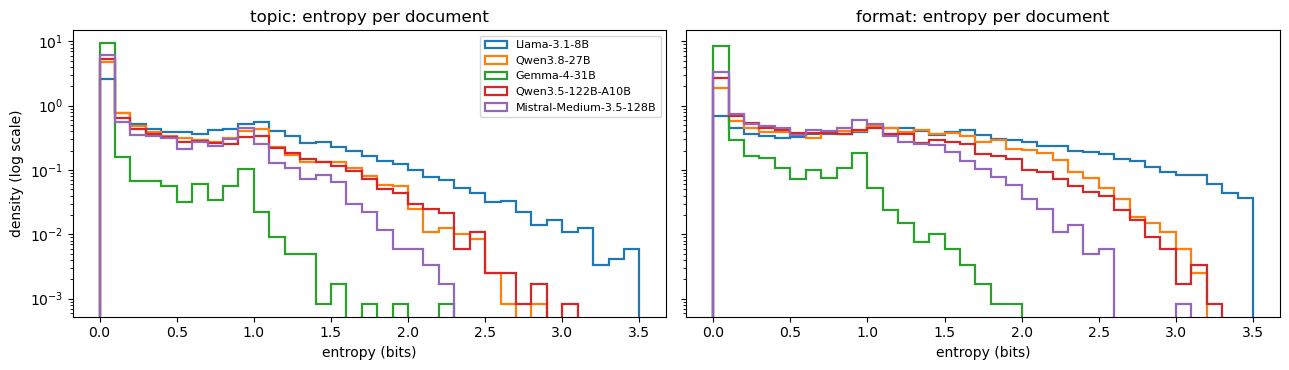

In [8]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(13, 3.8), sharey=True)
bins = [i * 0.1 for i in range(36)]
for ax, label_type in zip(axes, LABEL_TYPES):
    for model in MODELS:
        ax.hist([entropy_bits(r.logprobs) for r in pooled(model, label_type)], bins=bins,
                histtype="step", linewidth=1.6, density=True, label=model, color=COLORS[model])
    ax.set_yscale("log")
    ax.set_xlabel("entropy (bits)")
    ax.set_title(f"{label_type}: entropy per document")
axes[0].set_ylabel("density (log scale)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Letter bias

Labels are shuffled per document, so the letter a label was shown under should not
predict whether it wins. Pooled over languages (each language has its own letter
orders):

- **winner chi2:** chi-square test of the winning letter against uniform. With 26
  letters the 5% critical value is 37.7; with ~12,000 documents even small biases
  exceed it, so compare models rather than reading it as pass/fail.
- **winner position z:** how far the average winning position is from 12.5 (the
  unbiased value), in standard errors; negative = early letters favoured.
- **runner-up chi2** and **top-3 runner-up letters:** whether the probability left
  after the top label follows letters rather than content.

In [9]:
LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
bias_rows = []
for label_type in LABEL_TYPES:
    for model in MODELS:
        records = pooled(model, label_type)
        bias = letter_bias(records)
        runner_up = Counter(
            r.letter_positions[sorted(range(len(r.logprobs)), key=r.logprobs.__getitem__)[-2]] for r in records
        )
        top3 = runner_up.most_common(3)
        bias_rows.append({
            "label type": label_type,
            "model": model,
            "winner chi2": bias["winner_chi2"],
            "winner position z": bias["winner_mean_position_z"],
            "runner-up chi2": bias["runner_up_chi2"],
            "top-3 runner-up letters": ", ".join(f"{LETTERS[j]} {c / len(records):.0%}" for j, c in top3),
        })
letter_bias_table = pd.DataFrame(bias_rows)
display(letter_bias_table.round(2))

,label type,model,winner chi2,winner position z,runner-up chi2,top-3 runner-up letters
0,topic,Llama-3.1-8B,500.60,-15.18,282.71,"S 5%, K 5%, L 5%"
1,topic,Qwen3.8-27B,37.38,-2.55,4366.49,"A 12%, I 12%, B 6%"
2,topic,Gemma-4-31B,33.51,2.98,24182.79,"C 20%, S 18%, B 17%"
3,topic,Qwen3.5-122B-A10B,21.39,1.71,1083.97,"D 7%, S 6%, O 6%"
4,topic,Mistral-Medium-3.5-128B,55.38,-4.02,82.57,"B 5%, J 4%, D 4%"
5,format,Llama-3.1-8B,1375.50,-28.18,597.62,"K 6%, M 5%, L 5%"
6,format,Qwen3.8-27B,114.48,-9.03,346.63,"A 6%, I 5%, T 5%"
7,format,Gemma-4-31B,24.38,1.19,11920.26,"C 16%, B 14%, S 13%"
8,format,Qwen3.5-122B-A10B,56.70,-2.83,323.20,"S 5%, D 5%, O 5%"
9,format,Mistral-Medium-3.5-128B,97.12,-4.44,89.61,"K 4%, A 4%, B 4%"


## 4. Agreement between models

### Pairwise agreement

Share of (document, language) pairs where two models choose the same top label,
over all languages both models have.

In [10]:
def pairwise_agreement(label_type):
    """Top-1 agreement for every model pair, pooled over shared languages."""
    names = list(MODELS)
    matrix = pd.DataFrame(1.0, index=names, columns=names)
    for a, b in combinations(names, 2):
        agree = total = 0
        for lang in LANGUAGES:
            if (a, label_type, lang) in runs and (b, label_type, lang) in runs:
                pairs = zip(tops(a, label_type, lang), tops(b, label_type, lang))
                for x, y in pairs:
                    agree += x == y
                    total += 1
        matrix.loc[a, b] = matrix.loc[b, a] = agree / total
    return matrix


agreement_matrices = {label_type: pairwise_agreement(label_type) for label_type in LABEL_TYPES}
for label_type, matrix in agreement_matrices.items():
    print(f"{label_type}: top-1 agreement between models")
    display(matrix.round(3))

topic: top-1 agreement between models


,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
Llama-3.1-8B,1.000,0.675,0.644,0.671,0.670
Qwen3.8-27B,0.675,1.000,0.860,0.884,0.849
Gemma-4-31B,0.644,0.860,1.000,0.854,0.826
Qwen3.5-122B-A10B,0.671,0.884,0.854,1.000,0.837
Mistral-Medium-3.5-128B,0.670,0.849,0.826,0.837,1.000


format: top-1 agreement between models


,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
Llama-3.1-8B,1.000,0.371,0.326,0.366,0.390
Qwen3.8-27B,0.371,1.000,0.765,0.748,0.715
Gemma-4-31B,0.326,0.765,1.000,0.718,0.686
Qwen3.5-122B-A10B,0.366,0.748,0.718,1.000,0.691
Mistral-Medium-3.5-128B,0.390,0.715,0.686,0.691,1.000


**Plot.** The same matrices as heatmaps; brighter = more agreement.

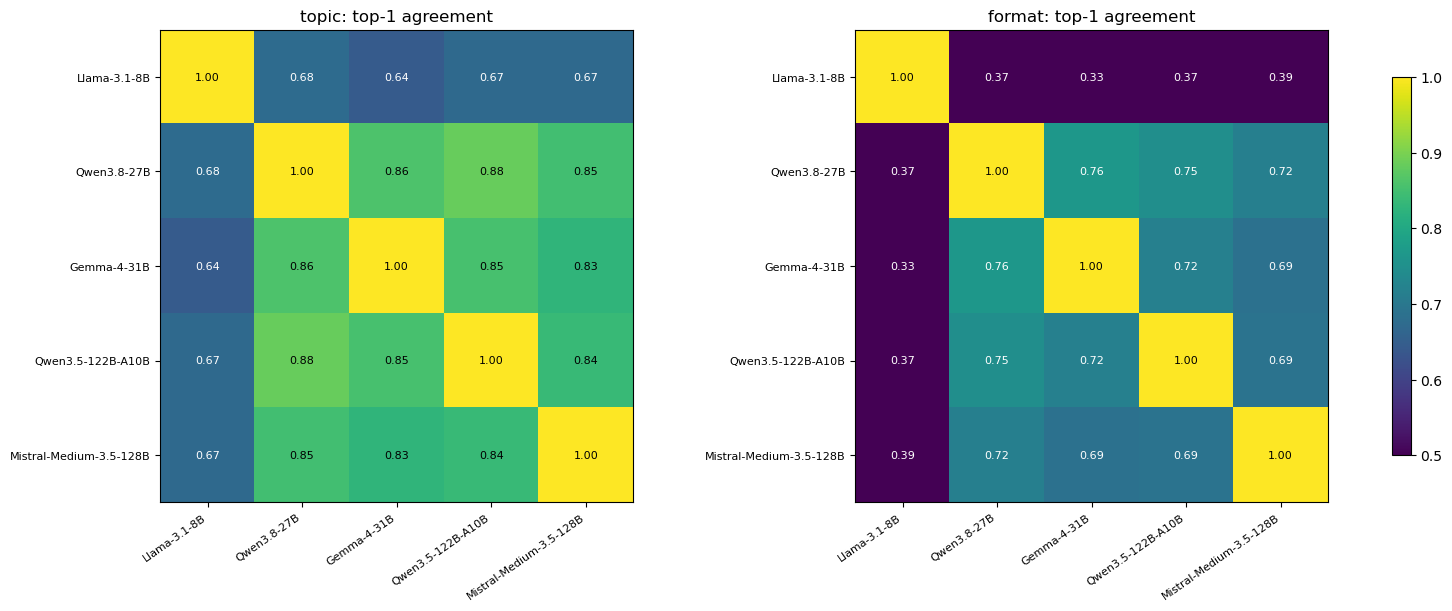

In [11]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(15, 6), constrained_layout=True)
for ax, (label_type, matrix) in zip(axes, agreement_matrices.items()):
    image = ax.imshow(matrix.values, vmin=0.5, vmax=1.0, cmap="viridis")
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.values[i, j]
            # Dark text on the bright upper part of the colour scale, white below.
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="black" if value >= 0.8 else "white")
    ax.set_xticks(range(len(matrix)))
    ax.set_xticklabels(matrix.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(matrix)))
    ax.set_yticklabels(matrix.index, fontsize=8)
    ax.set_title(f"{label_type}: top-1 agreement")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

### Agreement with the other models' consensus

Without human labels, the best stand-in for accuracy is whether a model agrees with
what the *other* models choose. For each model, on every (document, language) where
all five models have a label:

- **plurality agreement:** the other four models' most common label, when that is
  unique (ties are left out; coverage says how many documents remain).
- **strong-consensus agreement:** only documents where at least three of the other
  four agree. This is the most reliable subset: if three independent models agree and
  this one doesn't, it is probably this one that is wrong.
- **JSD to the others' mean:** divergence between the model's distribution and the
  average distribution of the others (lower = closer).
- **consensus log loss:** on the strong-consensus documents, −log2 of the probability
  the model gives the consensus label, averaged. This is a proper scoring rule: it
  rewards putting probability on the right label and punishes confident mistakes,
  which is what matters for soft labels. A model that is certain and wrong pays up to
  tens of bits on that document.
- **consensus calibration error:** on the same documents, whether the model's
  confidence matches how often it agrees with the consensus (expected calibration
  error over 10 confidence bins; 0 = perfectly calibrated).

A model can't vote for itself, so this doesn't automatically favour any model, but it
does reward agreeing with the majority, including on documents where the majority is
wrong.

In [12]:
consensus_rows = []
for label_type in LABEL_TYPES:
    complete_languages = [lang for lang in LANGUAGES if len(available(label_type, lang)) == len(MODELS)]
    top_cache = {(m, lang): tops(m, label_type, lang) for m in MODELS for lang in complete_languages}
    for model in MODELS:
        others = [m for m in MODELS if m != model]
        plural_agree = plural_total = strong_agree = strong_total = 0
        jsd = []
        log_loss = []           # -log2 p(consensus label), strong-consensus documents
        confidences, hits = [], []
        for lang in complete_languages:
            for k, d in enumerate(doc_ids[label_type]):
                votes = Counter(top_cache[(o, lang)][k] for o in others)
                (best, count), *rest = votes.most_common()
                own = top_cache[(model, lang)][k]
                if not rest or rest[0][1] < count:
                    plural_total += 1
                    plural_agree += own == best
                if count >= 3:
                    strong_total += 1
                    strong_agree += own == best
                    record = runs[(model, label_type, lang)][d]
                    log_loss.append(-record.logprobs[best] / math.log(2))
                    confidences.append(math.exp(max(record.logprobs)))
                    hits.append(own == best)
                # Mean distribution of the other models, back in log space for the JSD.
                mean = [statistics.fmean(math.exp(runs[(o, label_type, lang)][d].logprobs[i]) for o in others)
                        for i in range(len(labels[label_type]))]
                jsd.append(jensen_shannon_bits(runs[(model, label_type, lang)][d].logprobs,
                                               [math.log(p) if p > 0 else -1e9 for p in mean]))
        consensus_rows.append({
            "label type": label_type,
            "model": model,
            "languages": len(complete_languages),
            "plurality agreement": plural_agree / plural_total,
            "plurality coverage": plural_total / (len(complete_languages) * len(doc_ids[label_type])),
            "strong-consensus agreement": strong_agree / strong_total,
            "strong-consensus docs": strong_total,
            "JSD to others' mean (bits)": statistics.fmean(jsd),
            "consensus log loss (bits)": statistics.fmean(log_loss),
            "consensus calibration error": expected_calibration_error(confidences, hits, 10)[0],
        })
consensus = pd.DataFrame(consensus_rows)
display(consensus.round(3))
print("Languages where a model is missing are left out for all models, so every model is scored on the same documents.")

,label type,model,languages,plurality agreement,plurality coverage,strong-consensus agreement,strong-consensus docs,JSD to others' mean (bits),consensus log loss (bits),consensus calibration error
0,topic,Llama-3.1-8B,6,0.693,0.942,0.705,10966,0.230,1.603,0.122
1,topic,Qwen3.8-27B,6,0.919,0.929,0.945,10324,0.065,0.217,0.021
2,topic,Gemma-4-31B,6,0.883,0.937,0.906,10523,0.147,1.496,0.086
3,topic,Qwen3.5-122B-A10B,6,0.909,0.931,0.934,10405,0.079,0.268,0.007
4,topic,Mistral-Medium-3.5-128B,6,0.879,0.940,0.903,10605,0.101,0.415,0.038
5,format,Llama-3.1-8B,6,0.383,0.902,0.408,9589,0.479,4.215,0.297
6,format,Qwen3.8-27B,6,0.820,0.893,0.903,8196,0.123,0.419,0.060
7,format,Gemma-4-31B,6,0.778,0.900,0.853,8408,0.276,2.164,0.132
8,format,Qwen3.5-122B-A10B,6,0.787,0.899,0.866,8459,0.170,0.564,0.013
9,format,Mistral-Medium-3.5-128B,6,0.759,0.914,0.837,8660,0.189,0.691,0.048


Languages where a model is missing are left out for all models, so every model is scored on the same documents.


### Is the consensus biased toward one model family?

Two of the models are Qwen, and models of the same family can share errors. A Qwen
model's consensus then partly consists of its sibling, which could flatter both.
This check scores each model only against **voters from other families**, leaving
out the weak models in `WEAK_MODELS`, and only on documents where those voters are
**unanimous**. Models scored against the same voters (here the two Qwens, both
against Gemma + Mistral) can be compared directly; rows with different voters show
whether the picture holds, not exact differences.

In [13]:
family_rows = []
for label_type in LABEL_TYPES:
    complete_languages = [lang for lang in LANGUAGES if len(available(label_type, lang)) == len(MODELS)]
    for model in MODELS:
        voters = [m for m in MODELS if FAMILIES[m] != FAMILIES[model] and m not in WEAK_MODELS]
        agree = total = 0
        log_loss = []
        for lang in complete_languages:
            voter_tops = [tops(v, label_type, lang) for v in voters]
            own = runs[(model, label_type, lang)]
            for k, d in enumerate(doc_ids[label_type]):
                labels_chosen = {vt[k] for vt in voter_tops}
                if len(labels_chosen) == 1:
                    (label,) = labels_chosen
                    total += 1
                    agree += top_index(own[d].logprobs) == label
                    log_loss.append(-own[d].logprobs[label] / math.log(2))
        family_rows.append({
            "label type": label_type,
            "model": model,
            "voters": " + ".join(voters),
            "agreement with unanimous voters": agree / total,
            "log loss (bits)": statistics.fmean(log_loss),
            "documents": total,
        })
display(pd.DataFrame(family_rows).round(3))

,label type,model,voters,agreement with unanimous voters,log loss (bits),documents
0,topic,Llama-3.1-8B,Qwen3.8-27B + Gemma-4-31B + Qwen3.5-122B-A10B ...,0.758,1.228,8914
1,topic,Qwen3.8-27B,Gemma-4-31B + Mistral-Medium-3.5-128B,0.939,0.238,9917
2,topic,Gemma-4-31B,Qwen3.8-27B + Qwen3.5-122B-A10B + Mistral-Medi...,0.937,0.954,9512
3,topic,Qwen3.5-122B-A10B,Gemma-4-31B + Mistral-Medium-3.5-128B,0.930,0.305,9917
4,topic,Mistral-Medium-3.5-128B,Qwen3.8-27B + Gemma-4-31B + Qwen3.5-122B-A10B,0.922,0.328,9664
5,format,Llama-3.1-8B,Qwen3.8-27B + Gemma-4-31B + Qwen3.5-122B-A10B ...,0.453,3.747,6589
6,format,Qwen3.8-27B,Gemma-4-31B + Mistral-Medium-3.5-128B,0.892,0.448,8237
7,format,Gemma-4-31B,Qwen3.8-27B + Qwen3.5-122B-A10B + Mistral-Medi...,0.903,1.268,7298
8,format,Qwen3.5-122B-A10B,Gemma-4-31B + Mistral-Medium-3.5-128B,0.854,0.627,8237
9,format,Mistral-Medium-3.5-128B,Qwen3.8-27B + Gemma-4-31B + Qwen3.5-122B-A10B,0.859,0.601,7673


## 5. Multilingual consistency

### Each language against English

For every model, label type and non-English language, `compare` (from
`evaluate_multilingual_distributions.py`) measures:

- **top-1 agreement** and **Cohen's kappa** with the English labels of the same
  documents;
- **mean JSD** between the English and translated distributions;
- **normalized consistency:** 1 − JSD(parallel documents) / JSD(random document
  pairs). 1 means translations get the same distribution, 0 means no more similar
  than unrelated documents. Unlike raw JSD, it doesn't reward flat distributions.

Rows without an English run (e.g. a missing English file) are left out here; the
English-free comparison below covers them.

In [14]:
language_rows = []
for label_type in LABEL_TYPES:
    for model in MODELS:
        if (model, label_type, "english") not in runs:
            continue
        english = runs[(model, label_type, "english")]
        for lang in LANGUAGES[1:]:
            if (model, label_type, lang) not in runs:
                continue
            other = runs[(model, label_type, lang)]
            result = compare_with_english(
                [english[d] for d in doc_ids[label_type]],
                [other[d] for d in doc_ids[label_type]],
                labels[label_type],
                SEED,
            )
            language_rows.append({
                "label type": label_type,
                "model": model,
                "language": lang,
                "translation": TRANSLATION_MODEL[lang],
                "top-1 agreement": result["agreement"]["top1_agreement"],
                "kappa": result["agreement"]["cohen_kappa"],
                "mean JSD (bits)": result["soft"]["jsd_bits"]["mean"],
                "normalized consistency": result["soft"]["normalized_consistency"],
            })
by_language = pd.DataFrame(language_rows)
for label_type in LABEL_TYPES:
    print(f"{label_type}: top-1 agreement with English")
    display(by_language[by_language["label type"] == label_type]
            .pivot(index="model", columns="language", values="top-1 agreement").round(3))

topic: top-1 agreement with English


language,finnish,german,hungarian,icelandic,ukrainian
model,,,,,
Gemma-4-31B,0.897,0.916,0.903,0.892,0.910
Llama-3.1-8B,0.672,0.688,0.697,0.625,0.662
Mistral-Medium-3.5-128B,0.855,0.881,0.864,0.843,0.856
Qwen3.5-122B-A10B,0.888,0.906,0.894,0.890,0.898
Qwen3.8-27B,0.902,0.912,0.910,0.890,0.915


format: top-1 agreement with English


language,finnish,german,hungarian,icelandic,ukrainian
model,,,,,
Gemma-4-31B,0.782,0.818,0.794,0.774,0.802
Llama-3.1-8B,0.456,0.508,0.476,0.426,0.479
Mistral-Medium-3.5-128B,0.749,0.768,0.736,0.706,0.730
Qwen3.5-122B-A10B,0.736,0.773,0.745,0.724,0.754
Qwen3.8-27B,0.796,0.806,0.789,0.774,0.806


**Summary per model:** the mean over languages, the **worst** language (a model is
only as useful as its weakest language), and the means for languages translated by
the larger (tower72b) and smaller (tower9b) Tower model. If agreement drops for
tower9b languages across all models, that's translation quality, not the labelling
model.

In [15]:
summary_rows = []
for (label_type, model), group in by_language.groupby(["label type", "model"], sort=False):
    summary_rows.append({
        "label type": label_type,
        "model": model,
        "mean agreement": group["top-1 agreement"].mean(),
        "worst language": group.loc[group["top-1 agreement"].idxmin(), "language"],
        "worst agreement": group["top-1 agreement"].min(),
        "tower72b mean": group.loc[group["translation"] == "tower72b", "top-1 agreement"].mean(),
        "tower9b mean": group.loc[group["translation"] == "tower9b", "top-1 agreement"].mean(),
        "mean normalized consistency": group["normalized consistency"].mean(),
    })
multilingual_summary = pd.DataFrame(summary_rows)
display(multilingual_summary.round(3))

,label type,model,mean agreement,worst language,worst agreement,tower72b mean,tower9b mean,mean normalized consistency
0,topic,Llama-3.1-8B,0.669,icelandic,0.625,0.680,0.661,0.759
1,topic,Qwen3.8-27B,0.906,icelandic,0.890,0.907,0.905,0.959
2,topic,Gemma-4-31B,0.904,icelandic,0.892,0.907,0.902,0.910
3,topic,Qwen3.5-122B-A10B,0.895,finnish,0.888,0.897,0.894,0.944
4,topic,Mistral-Medium-3.5-128B,0.860,icelandic,0.843,0.868,0.854,0.917
5,format,Llama-3.1-8B,0.469,icelandic,0.426,0.482,0.460,0.586
6,format,Qwen3.8-27B,0.794,icelandic,0.774,0.801,0.790,0.897
7,format,Gemma-4-31B,0.794,icelandic,0.774,0.800,0.790,0.800
8,format,Qwen3.5-122B-A10B,0.747,icelandic,0.724,0.755,0.741,0.840
9,format,Mistral-Medium-3.5-128B,0.738,icelandic,0.706,0.759,0.724,0.828


**Plot.** Agreement with English per language, one line per model. Lines that drop
together at the same languages point to translation quality; a line that sits below
the others throughout belongs to a less consistent model.

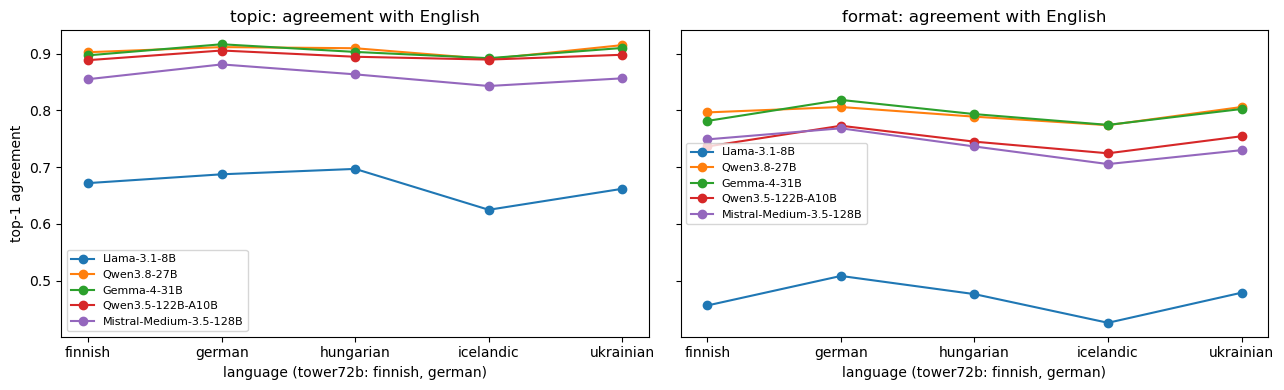

In [16]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(13, 4), sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    table = by_language[by_language["label type"] == label_type]
    for model in MODELS:
        rows = table[table["model"] == model]
        if len(rows):
            ax.plot(rows["language"], rows["top-1 agreement"], marker="o", label=model, color=COLORS[model])
    ax.set_title(f"{label_type}: agreement with English")
    ax.set_xlabel("language (tower72b: finnish, german)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("top-1 agreement")
fig.tight_layout()
plt.show()

### Consistency without English

The comparison with English needs an English run. This version uses only the five
translated languages, so every model is measured the same way even if an English
file is missing:

- **pairwise agreement:** mean top-1 agreement over all 10 pairs of translated
  languages;
- **unanimous:** share of documents where all five translations get the same top
  label;
- **generalized JSD:** divergence among the five translations' distributions per
  document (0 = identical), averaged.

In [17]:
translated = LANGUAGES[1:]
no_english_rows = []
for label_type in LABEL_TYPES:
    for model in MODELS:
        langs = [lang for lang in translated if (model, label_type, lang) in runs]
        if len(langs) < len(translated):
            print(f"{model} / {label_type}: missing translated languages; left out")
            continue
        top_lists = {lang: tops(model, label_type, lang) for lang in langs}
        pair_agreement = statistics.fmean(
            sum(x == y for x, y in zip(top_lists[a], top_lists[b])) / len(doc_ids[label_type])
            for a, b in combinations(langs, 2)
        )
        unanimous = sum(len({top_lists[lang][k] for lang in langs}) == 1 for k in range(len(doc_ids[label_type])))
        gjsd = statistics.fmean(
            generalized_jensen_shannon_bits([runs[(model, label_type, lang)][d].logprobs for lang in langs])
            for d in doc_ids[label_type]
        )
        no_english_rows.append({
            "label type": label_type,
            "model": model,
            "pairwise agreement (translations)": pair_agreement,
            "unanimous (5 translations)": unanimous / len(doc_ids[label_type]),
            "generalized JSD (bits)": gjsd,
        })
no_english = pd.DataFrame(no_english_rows)
display(no_english.round(3))

,label type,model,pairwise agreement (translations),unanimous (5 translations),generalized JSD (bits)
0,topic,Llama-3.1-8B,0.670,0.424,0.366
1,topic,Qwen3.8-27B,0.904,0.812,0.068
2,topic,Gemma-4-31B,0.903,0.810,0.142
3,topic,Qwen3.5-122B-A10B,0.897,0.799,0.084
4,topic,Mistral-Medium-3.5-128B,0.866,0.744,0.127
5,format,Llama-3.1-8B,0.489,0.196,0.549
6,format,Qwen3.8-27B,0.805,0.632,0.135
7,format,Gemma-4-31B,0.809,0.646,0.294
8,format,Qwen3.5-122B-A10B,0.779,0.598,0.195
9,format,Mistral-Medium-3.5-128B,0.760,0.555,0.229


## 6. Which labels are unstable across languages?

For each label, among documents whose **English** top label is that label: the share
where all six languages agree. Low values mark labels whose boundaries shift in
translation; if they are low for every model, the label definition (or the
translations) is the problem, not the model. Labels with fewer than 20 such
documents are left blank, because their shares are too noisy; so is a model's whole
column if it lacks a language (this needs all six).

In [18]:
MIN_DOCS = 20
stability = {}
for label_type in LABEL_TYPES:
    table = pd.DataFrame(index=labels[label_type], columns=list(MODELS), dtype=float)
    for model in MODELS:
        if any((model, label_type, lang) not in runs for lang in LANGUAGES):
            continue
        top_lists = {lang: tops(model, label_type, lang) for lang in LANGUAGES}
        for i, name in enumerate(labels[label_type]):
            docs = [k for k, t in enumerate(top_lists["english"]) if t == i]
            if len(docs) >= MIN_DOCS:
                table.loc[name, model] = sum(len({top_lists[lang][k] for lang in LANGUAGES}) == 1 for k in docs) / len(docs)
    stability[label_type] = table
    print(f"{label_type}: share of documents where all six languages agree, by English top label")
    display(table.round(2))

topic: share of documents where all six languages agree, by English top label


,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
Adult,0.30,NaN,NaN,NaN,NaN
Art & Design,NaN,0.70,0.71,0.59,0.56
Software Dev.,0.22,0.86,0.89,0.90,0.76
Crime & Law,0.28,0.72,NaN,0.64,0.57
Education & Jobs,0.41,0.77,0.73,0.81,0.72
Hardware,0.24,0.74,0.74,0.78,0.68
Entertainment,0.26,0.83,0.80,0.77,0.75
Social Life,0.37,0.70,0.68,0.66,0.55
Fashion & Beauty,0.20,NaN,NaN,NaN,NaN
Finance & Business,0.42,0.80,0.80,0.79,0.78


format: share of documents where all six languages agree, by English top label


,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
Academic Writing,0.17,0.68,0.67,0.60,0.63
Content Listing,0.04,0.53,0.59,0.32,0.41
Creative Writing,0.38,0.76,0.85,0.71,0.77
Customer Support,0.02,0.67,NaN,0.39,0.33
Comment Section,0.05,0.51,0.56,0.47,0.49
FAQ,0.00,0.72,0.77,0.76,0.70
Truncated,NaN,0.25,0.37,0.26,0.19
Knowledge Article,0.19,0.67,0.69,0.78,0.57
Legal Notices,NaN,NaN,NaN,NaN,NaN
Listicle,0.15,0.78,0.80,0.60,0.63


**Plot.** The same tables as heatmaps (blank = too few documents, or the model lacks a
language). Rows that are dark for every model are unstable labels.

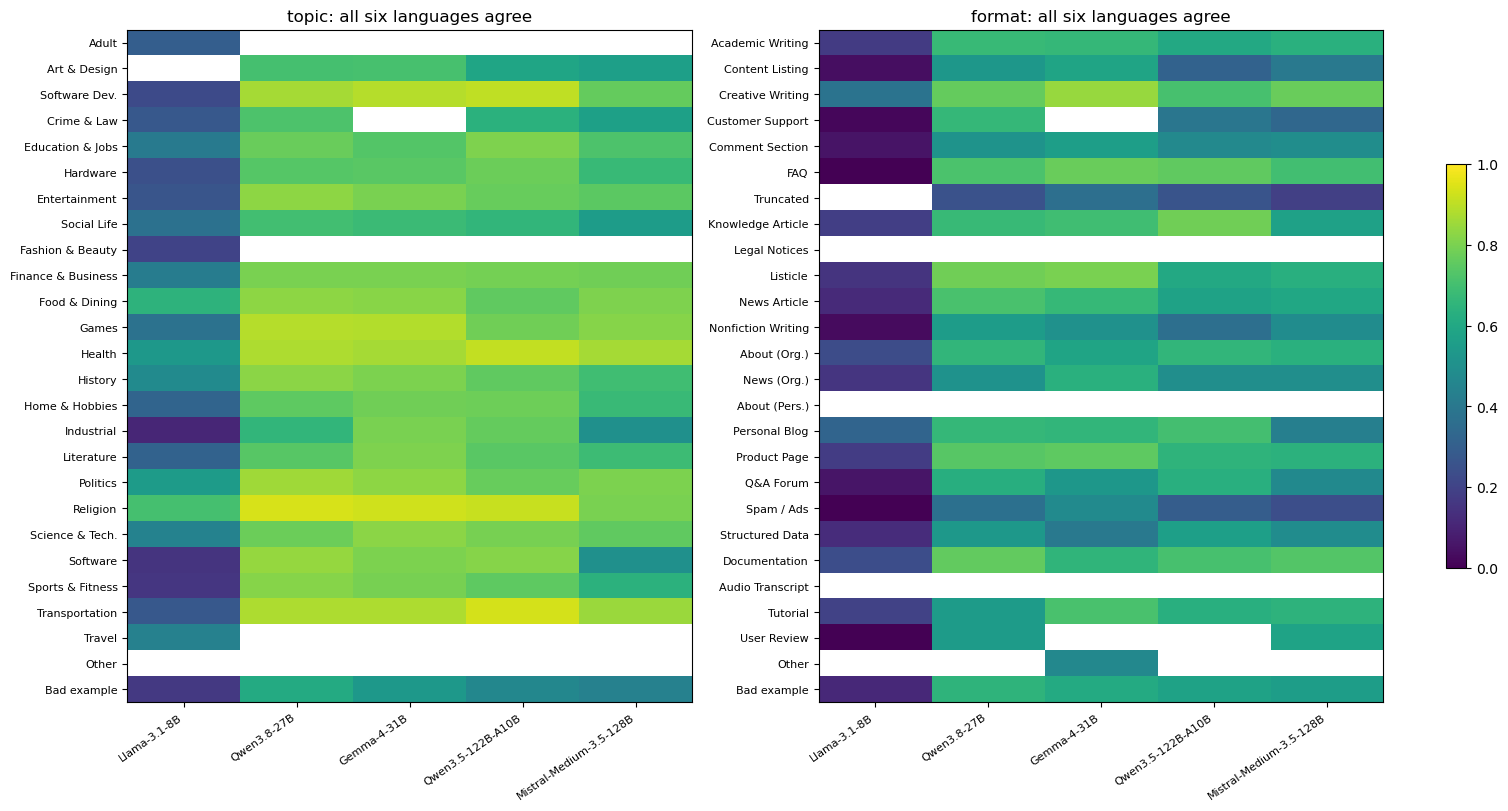

In [19]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(15, 8), constrained_layout=True)
for ax, (label_type, table) in zip(axes, stability.items()):
    image = ax.imshow(table.values.astype(float), vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index, fontsize=8)
    ax.set_title(f"{label_type}: all six languages agree")
fig.colorbar(image, ax=axes, shrink=0.6)
plt.show()

## 7. Label mix

The share of documents whose top label is each label (English, or the first language
a model has), per model, and each model's **mix divergence**: the JSD between its
label shares and the average shares of the other models. A high divergence means the
model systematically prefers or avoids some labels compared with its peers.

In [20]:
def label_shares(model, label_type):
    """Share of documents per top label, in the first available language."""
    lang = next(lang for lang in LANGUAGES if (model, label_type, lang) in runs)
    counts = Counter(tops(model, label_type, lang))
    n = len(doc_ids[label_type])
    return [counts[i] / n for i in range(len(labels[label_type]))]


def share_jsd(p, q):
    """Jensen-Shannon divergence between two share vectors, in bits."""
    m = [(a + b) / 2 for a, b in zip(p, q)]
    h = lambda v: -sum(x * math.log2(x) for x in v if x > 0)
    return max(0.0, h(m) - (h(p) + h(q)) / 2)


mix_rows = []
for label_type in LABEL_TYPES:
    shares = {model: label_shares(model, label_type) for model in MODELS}
    display(pd.DataFrame(shares, index=labels[label_type]).round(3).rename_axis(f"{label_type} label"))
    for model in MODELS:
        others = [shares[o] for o in MODELS if o != model]
        mean_others = [statistics.fmean(column) for column in zip(*others)]
        mix_rows.append({"label type": label_type, "model": model, "mix divergence (bits)": share_jsd(shares[model], mean_others)})
mix = pd.DataFrame(mix_rows)
display(mix.round(4))

,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
topic label,,,,,
Adult,0.010,0.004,0.005,0.006,0.006
Art & Design,0.010,0.014,0.020,0.017,0.020
Software Dev.,0.044,0.044,0.041,0.042,0.052
Crime & Law,0.014,0.012,0.010,0.012,0.015
Education & Jobs,0.108,0.116,0.079,0.104,0.112
Hardware,0.022,0.019,0.020,0.020,0.020
Entertainment,0.046,0.068,0.070,0.062,0.068
Social Life,0.018,0.022,0.024,0.019,0.029
Fashion & Beauty,0.010,0.008,0.007,0.007,0.006


,Llama-3.1-8B,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B
format label,,,,,
Academic Writing,0.076,0.018,0.015,0.024,0.020
Content Listing,0.014,0.056,0.070,0.028,0.056
Creative Writing,0.044,0.019,0.020,0.019,0.022
Customer Support,0.026,0.012,0.008,0.012,0.015
Comment Section,0.037,0.082,0.070,0.073,0.090
FAQ,0.012,0.020,0.018,0.020,0.016
Truncated,0.004,0.065,0.079,0.100,0.055
Knowledge Article,0.130,0.092,0.072,0.087,0.075
Legal Notices,0.004,0.002,0.002,0.002,0.002


,label type,model,mix divergence (bits)
0,topic,Llama-3.1-8B,0.0115
1,topic,Qwen3.8-27B,0.0016
2,topic,Gemma-4-31B,0.0050
3,topic,Qwen3.5-122B-A10B,0.0031
4,topic,Mistral-Medium-3.5-128B,0.0060
5,format,Llama-3.1-8B,0.1100
6,format,Qwen3.8-27B,0.0092
7,format,Gemma-4-31B,0.0203
8,format,Qwen3.5-122B-A10B,0.0239
9,format,Mistral-Medium-3.5-128B,0.0123


## 8. Cost per 1,000 documents

Parsed from the job logs (`logs/distribution_*.err`): for each completed run of a
model in `MODELS` that labelled exactly the documents in the result files, the
runtime from the first to the last log line (model loading included, but not the few
seconds before Python starts) and the GPUs used. Billing follows CSC's formula,
`BU = GPUs × 200 × hours`; the table shows the median over each model's runs.

In [21]:
def parse_log(path):
    """Model, label type, GPUs, documents and runtime of one completed job, or None."""
    text = path.read_text(encoding="utf-8", errors="replace")
    arg = lambda name: (re.search(rf"\[INFO\]\s+{name}: (.*)", text) or [None, None])[1]
    done = re.search(r"Completed (\d+) new documents", text)
    stamps = re.findall(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d),\d+ \[", text, re.M)
    if not done or not stamps or arg("model_name") is None:
        return None
    start, end = (datetime.strptime(s, "%Y-%m-%d %H:%M:%S") for s in (stamps[0], stamps[-1]))
    return {
        "model name": arg("model_name").strip().split("/")[-1],
        "label type": arg("label_type").strip(),
        "gpus": int(arg("tensor_parallel_size")),
        "documents": int(done.group(1)),
        "minutes": (end - start).total_seconds() / 60,
    }


jobs = [row for row in map(parse_log, sorted(LOGS_DIR.glob("distribution_*.err"))) if row]
names = {name: model for model, name in MODELS.items()}
expected = len(next(iter(doc_ids.values())))
jobs = pd.DataFrame([dict(job, model=names[job["model name"]]) for job in jobs
                     if job["model name"] in names and job["documents"] == expected])
jobs["BU per 1000 docs"] = jobs["gpus"] * BU_PER_GPU_HOUR * jobs["minutes"] / 60 / jobs["documents"] * 1000
cost = (jobs.groupby(["model", "label type"])
            .agg(runs=("minutes", "size"), gpus=("gpus", "median"), minutes_per_run=("minutes", "median"),
                 bu_per_1000_docs=("BU per 1000 docs", "median"))
            .reset_index())
display(cost.round(1))

,model,label type,runs,gpus,minutes_per_run,bu_per_1000_docs
0,Gemma-4-31B,format,6,1.0,32.8,54.8
1,Gemma-4-31B,topic,6,1.0,25.8,42.9
2,Llama-3.1-8B,format,6,1.0,3.7,6.2
3,Llama-3.1-8B,topic,6,1.0,3.3,5.5
4,Mistral-Medium-3.5-128B,format,6,4.0,11.3,75.3
5,Mistral-Medium-3.5-128B,topic,7,4.0,10.0,66.7
6,Qwen3.5-122B-A10B,format,6,4.0,9.4,62.5
7,Qwen3.5-122B-A10B,topic,6,4.0,10.7,71.6
8,Qwen3.8-27B,format,6,1.0,19.4,32.4
9,Qwen3.8-27B,topic,2,1.0,16.4,27.4


## 9. Agreement with WebOrganizer-405B (if available)

Runs from `array_generate_distribution_weborganizer.sh` label WebOrganizer's own
documents, so they can be compared with WebOrganizer's Llama-3.1-405B labels. Our
`Other` and `Bad example` are routed back to WebOrganizer's 24 labels for the
comparison (their probability removed, the rest renormalized). If no such runs exist,
this section only says so.

In [22]:
wo_rows = []
for label_type in LABEL_TYPES:
    all_names, all_short = load_label_names(LABEL_FILES[label_type])
    wo_names, wo_short, added = weborganizer_label_subset(all_names, all_short)
    for model, name in MODELS.items():
        path = WO_RESULTS_DIR / name / f"{label_type}.jsonl"
        if not path.exists():
            continue
        run_labels, records = read_distribution_file(path)
        ids = list(records)
        offsets = list(range(0, math.ceil(len(ids) / 100) * 100, 100))
        dataset = WO_DATASETS[label_type]
        rows = fetch_rows(dataset, offsets, CACHE_DIR / f"{dataset.split('/')[-1]}_first{len(offsets) * 100}.jsonl")
        reference = {r.doc_id: r for r in (reference_record(row, wo_names, k) for k, row in enumerate(rows, 1))}
        missing_ids = [d for d in ids if d not in reference]
        assert not missing_ids, f"{path}: {len(missing_ids)} documents not in the first {len(rows)} reference rows"
        full = [records[d] for d in ids]
        keep = [run_labels.index(s) for s in wo_short]
        routed = [restrict_to_labels(r, keep) for r in full]
        report = evaluate_against_reference(routed, [reference[d] for d in ids], wo_short, 10, candidates_full=full)
        routing = label_routing(full, run_labels, added) if added else None
        wo_rows.append({
            "label type": label_type, "model": model, "documents": len(ids),
            "top-1 agreement": report["agreement"]["top1_agreement"],
            "kappa": report["agreement"]["cohen_kappa"],
            "WO label in top 2": report["agreement"]["reference_top_in_candidate_top2"],
            "mean JSD (bits)": report["soft"]["jsd_bits"]["mean"],
            "WO label log loss (bits)": report["soft"]["reference_label_log_loss_bits"],
            "calibration error": report["calibration"]["ece"],
            "routed top label": routing["share_top_label_routed"] if routing else 0.0,
        })
if wo_rows:
    wo_agreement = pd.DataFrame(wo_rows)
    display(wo_agreement.round(3))
else:
    wo_agreement = None
    print("No WebOrganizer-405B runs found in", WO_RESULTS_DIR)
    print("Run hpc/roihu/array_generate_distribution_weborganizer.sh <model> for each model to add this criterion.")

No WebOrganizer-405B runs found in /scratch/project_2020507/users/tarkkaot/MultilingualWebOrganizer/results/distribution/weborganizer-405B
Run hpc/roihu/array_generate_distribution_weborganizer.sh <model> for each model to add this criterion.


## 10. Decision table

The main numbers from the sections above, one row per model and label type, with a
rank per criterion (1 = best) and the mean rank. Direction of "better":

| Criterion | Better | From |
|---|---|---|
| strong-consensus agreement | higher | section 4 |
| consensus log loss | lower | section 4 |
| consensus calibration error | lower | section 4 |
| mean / worst agreement with English | higher | section 5 |
| pairwise agreement (translations) | higher | section 5 |
| letter position \|z\| | lower | section 3 |
| mix divergence | lower | section 7 |
| BU per 1,000 docs | lower | section 8 |
| WebOrganizer agreement | higher | section 9, if available |

**Mean entropy** and **fallback share** are shown but not ranked: neither has a
"better" direction on its own. High entropy can mean honest uncertainty or a weak
model; few fallback labels can mean good fit or a model that avoids them. The log
loss and calibration error capture the useful part of confidence instead.

The mean rank weighs all ranked criteria equally, which is a judgement call:
consistency and consensus quality matter more for the use case than a few BU of cost.
Read the ranks together with the numbers.

In [23]:
decision = confidence[["label type", "model", "mean entropy (bits)"]].copy()
decision["fallback share"] = confidence["Other top"] + confidence["Bad example top"]
decision = decision.merge(consensus[["label type", "model", "strong-consensus agreement", "consensus log loss (bits)",
                                     "consensus calibration error"]], on=["label type", "model"])
decision = decision.merge(multilingual_summary[["label type", "model", "mean agreement", "worst agreement"]],
                          on=["label type", "model"], how="left")
decision = decision.merge(no_english[["label type", "model", "pairwise agreement (translations)"]],
                          on=["label type", "model"], how="left")
decision = decision.merge(letter_bias_table[["label type", "model", "winner position z"]], on=["label type", "model"])
decision["letter position |z|"] = decision.pop("winner position z").abs()
decision = decision.merge(mix, on=["label type", "model"])
decision = decision.merge(cost[["label type", "model", "bu_per_1000_docs"]], on=["label type", "model"], how="left")
if wo_agreement is not None:
    decision = decision.merge(wo_agreement[["label type", "model", "top-1 agreement"]]
                              .rename(columns={"top-1 agreement": "WO agreement"}), on=["label type", "model"], how="left")

higher_is_better = {
    "strong-consensus agreement": True, "consensus log loss (bits)": False, "consensus calibration error": False,
    "mean agreement": True, "worst agreement": True, "pairwise agreement (translations)": True,
    "letter position |z|": False, "mix divergence (bits)": False, "bu_per_1000_docs": False, "WO agreement": True,
}
ranked = decision.copy()
rank_columns = []
for column, higher in higher_is_better.items():
    if column in ranked:
        ranked[f"rank: {column}"] = ranked.groupby("label type")[column].rank(ascending=not higher, method="min")
        rank_columns.append(f"rank: {column}")
ranked["mean rank"] = ranked[rank_columns].mean(axis=1)
for label_type in LABEL_TYPES:
    print(f"{label_type}:")
    display(ranked[ranked["label type"] == label_type].drop(columns="label type").set_index("model")
            .sort_values("mean rank").round(3).T)

topic:


model,Qwen3.8-27B,Qwen3.5-122B-A10B,Gemma-4-31B,Mistral-Medium-3.5-128B,Llama-3.1-8B
mean entropy (bits),0.403,0.369,0.039,0.267,0.716
fallback share,0.039,0.051,0.046,0.031,0.022
strong-consensus agreement,0.945,0.934,0.906,0.903,0.705
consensus log loss (bits),0.217,0.268,1.496,0.415,1.603
consensus calibration error,0.021,0.007,0.086,0.038,0.122
mean agreement,0.906,0.895,0.904,0.860,0.669
worst agreement,0.890,0.888,0.892,0.843,0.625
pairwise agreement (translations),0.904,0.897,0.903,0.866,0.670
letter position |z|,2.546,1.714,2.984,4.015,15.176
mix divergence (bits),0.002,0.003,0.005,0.006,0.012


format:


model,Qwen3.8-27B,Gemma-4-31B,Qwen3.5-122B-A10B,Mistral-Medium-3.5-128B,Llama-3.1-8B
mean entropy (bits),0.909,0.080,0.706,0.552,1.302
fallback share,0.090,0.088,0.116,0.053,0.036
strong-consensus agreement,0.903,0.853,0.866,0.837,0.408
consensus log loss (bits),0.419,2.164,0.564,0.691,4.215
consensus calibration error,0.060,0.132,0.013,0.048,0.297
mean agreement,0.794,0.794,0.747,0.738,0.469
worst agreement,0.774,0.774,0.724,0.706,0.426
pairwise agreement (translations),0.805,0.809,0.779,0.760,0.489
letter position |z|,9.026,1.194,2.826,4.439,28.182
mix divergence (bits),0.009,0.020,0.024,0.012,0.110


## Appendix: spot checks of the fallback labels

Documents (English) where at least three models agree on `Other` or `Bad example`,
with the start of the text, to judge whether the fallback labels are used as
intended: `Other` for pages truly outside every category, `Bad example` for
unusable content. `SPOT_CHECKS` sets how many documents to show per label.

In [24]:
SPOT_CHECKS = 4
PREVIEW_CHARS = 400


def english_texts(label_type, wanted):
    """Read the text of the wanted documents from the first English run."""
    model = next(m for m in MODELS if (m, label_type, "english") in runs)
    path = RESULTS_DIR / f"{MODELS[model]}-annotations" / label_type / "english-parallel.jsonl"
    texts = {}
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            record = json.loads(line)
            if record["id"] in wanted:
                texts[record["id"]] = record["text"]
    return texts


for label_type in LABEL_TYPES:
    voters = available(label_type, "english")
    top_lists = {m: tops(m, label_type, "english") for m in voters}
    for name in FALLBACK:
        index = labels[label_type].index(name)
        chosen = [(k, sum(top_lists[m][k] == index for m in voters)) for k in range(len(doc_ids[label_type]))]
        chosen = [(k, votes) for k, votes in chosen if votes >= 3]
        print(f"=== {label_type} / {name}: {len(chosen)} documents with at least 3 of {len(voters)} English votes")
        sample = chosen[:SPOT_CHECKS]
        texts = english_texts(label_type, {doc_ids[label_type][k] for k, _ in sample})
        for k, votes in sample:
            others = Counter(labels[label_type][top_lists[m][k]] for m in voters if top_lists[m][k] != index)
            text = " ".join(texts[doc_ids[label_type][k]].split())[:PREVIEW_CHARS]
            print(f"--- {votes} votes; other models chose: {dict(others) or '-'}")
            print(f"    {text}")
        print()

=== topic / Other: 4 documents with at least 3 of 5 English votes
--- 3 votes; other models chose: {'Religion': 2}
    Abigay Name Details Abigay is the Jamaican version of Abigail. It means `the joy or happiness of Yahweh` or father of rejoicing. Origin american Religion christianity Gender Girl Lucky Number 9 Sort Infomation For Abigay name. Abigay is a american Girl name. The name Abigay is a very beautiful american name that begins with the letter A. This name is very good for Girls which means Abigay is the J
--- 3 votes; other models chose: {'Religion': 1, 'Literature': 1}
    How to pronounce Gajeufsky? Voice Pronunciations for Gajeufsky Click and hear the voice pronunciation multiple times and learn how to pronounce the name Gajeufsky. Pronunciations loading.. Please wait.. Gajeufsky name popularity Gajeufsky is currently not ranked in U.S. births Gajeufsky is currently not in the top 100 on the Baby Names Popularity Charts Meaning of each letter in Gajeufsky G Gallan
--- 3 vot